# Oasis Infobyte Internship — Level 2, Task 03: Fraud Detection

## Objective

The objective of this project is to identify potentially fraudulent credit card transactions using machine learning techniques.

The project focuses on:
- Understanding transaction data.
- Performing exploratory data analysis (EDA).
- Identifying patterns associated with fraudulent transactions.
- Handling class imbalance.
- Training and comparing classification models.
- Evaluating fraud detection performance using suitable metrics.
- Identifying the features that contribute to fraud prediction.

In [33]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [34]:
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [35]:
# Load the dataset
from google.colab import files
uploaded = files.upload()

Saving credit_card_fraud_10k.csv to credit_card_fraud_10k (1).csv


In [36]:
df = pd.read_csv("credit_card_fraud_10k.csv")
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset shape: (10000, 10)


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [37]:
# Inspect the dataset
print("First 5 rows:")
display(df.head())
print("Last 5 rows:")
display(df.tail())
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()

First 5 rows:


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


Last 5 rows:


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
9995,9996,350.91,22,Food,0,0,99,4,37,0
9996,9997,410.04,5,Clothing,0,0,70,3,25,0
9997,9998,527.75,21,Electronics,0,0,44,2,45,0
9998,9999,91.20,2,Electronics,0,0,38,0,37,0
9999,10000,44.06,2,Clothing,0,0,38,0,66,0


Dataset dimensions: (10000, 10)

Column names:
['transaction_id', 'amount', 'transaction_hour', 'merchant_category', 'foreign_transaction', 'location_mismatch', 'device_trust_score', 'velocity_last_24h', 'cardholder_age', 'is_fraud']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  object 
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), object

In [38]:
df.describe(include="all")

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
count,10000.00000,10000.000000,10000.000000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
unique,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,Food,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,2093,NaN,NaN,NaN,NaN,NaN,NaN
mean,5000.50000,175.949849,11.593300,NaN,0.097800,0.085700,61.798900,2.008900,43.468700,0.015100
std,2886.89568,175.392827,6.922708,NaN,0.297059,0.279935,21.487053,1.432559,14.979147,0.121957
min,1.00000,0.000000,0.000000,NaN,0.000000,0.000000,25.000000,0.000000,18.000000,0.000000
25%,2500.75000,50.905000,6.000000,NaN,0.000000,0.000000,43.000000,1.000000,30.000000,0.000000
50%,5000.50000,122.095000,12.000000,NaN,0.000000,0.000000,62.000000,2.000000,44.000000,0.000000
75%,7500.25000,242.480000,18.000000,NaN,0.000000,0.000000,80.000000,3.000000,56.000000,0.000000


## 4. Data Cleaning

Data cleaning helps ensure that the dataset is suitable for analysis.

We will:
- Check for missing values.
- Check for duplicate records.
- Check data types.
- Validate the target column.
- Check the range of important numerical features.

The transaction identifier is retained in the original dataset but
will be excluded from model training because it is an identifier
rather than a meaningful transaction characteristic.

In [39]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nData types:")
print(df.dtypes)
print("\nTarget values:")
print(df["is_fraud"].value_counts(dropna=False))

Missing values in each column:
transaction_id         0
amount                 0
transaction_hour       0
merchant_category      0
foreign_transaction    0
location_mismatch      0
device_trust_score     0
velocity_last_24h      0
cardholder_age         0
is_fraud               0
dtype: int64

Total missing values: 0

Duplicate rows: 0

Data types:
transaction_id           int64
amount                 float64
transaction_hour         int64
merchant_category       object
foreign_transaction      int64
location_mismatch        int64
device_trust_score       int64
velocity_last_24h        int64
cardholder_age           int64
is_fraud                 int64
dtype: object

Target values:
is_fraud
0    9849
1     151
Name: count, dtype: int64


In [40]:
# Remove exact duplicate rows, if any
df = df.drop_duplicates().copy()

# Remove rows with missing values, if any
df = df.dropna().copy()

# Validate target values
print("Unique target values:", sorted(df["is_fraud"].unique()))
if not set(df["is_fraud"].unique()).issubset({0, 1}):
    raise ValueError("Unexpected values found in is_fraud.")

print("\nDataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())

Unique target values: [np.int64(0), np.int64(1)]

Dataset shape after cleaning: (10000, 10)
Remaining missing values: 0
Remaining duplicate rows: 0


## 5. Exploratory Data Analysis

### 5.1 Distribution of Fraudulent and Legitimate Transactions

We first examine the distribution of the target variable.

This helps us understand whether fraudulent and legitimate transactions
are represented equally in the dataset.

Transaction counts:
is_fraud
0    9849
1     151
Name: count, dtype: int64


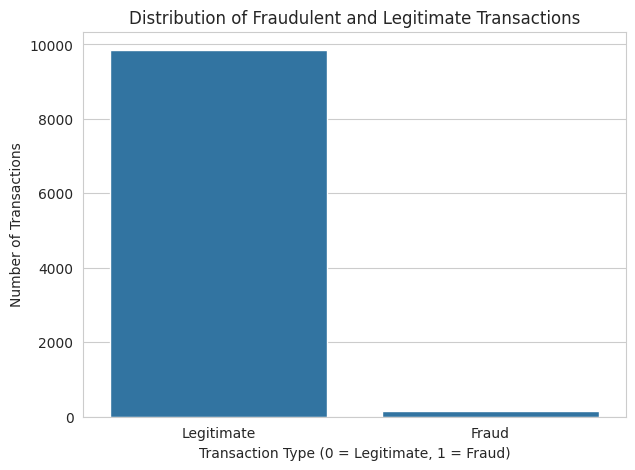

In [41]:
fraud_counts = df["is_fraud"].value_counts().sort_index()
print("Transaction counts:")
print(fraud_counts)
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="is_fraud")
plt.title("Distribution of Fraudulent and Legitimate Transactions")
plt.xlabel("Transaction Type (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.show()

In [42]:
fraud_percentages = df["is_fraud"].value_counts(normalize=True) * 100
print("Transaction percentages:")
print(fraud_percentages.round(2))

Transaction percentages:
is_fraud
0    98.49
1     1.51
Name: proportion, dtype: float64


### 5.2 Transaction Amount Distribution

The transaction amount represents the monetary value of each transaction.

We visualize its distribution to understand typical transaction values
and identify unusually large amounts.

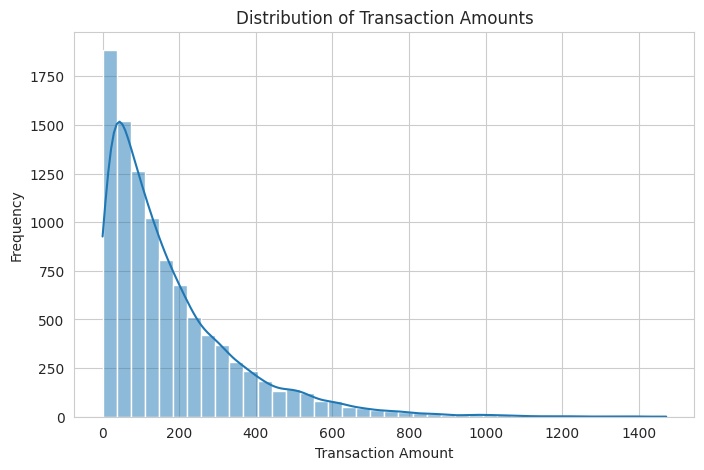

In [43]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df,x="amount",bins=40,kde=True)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()

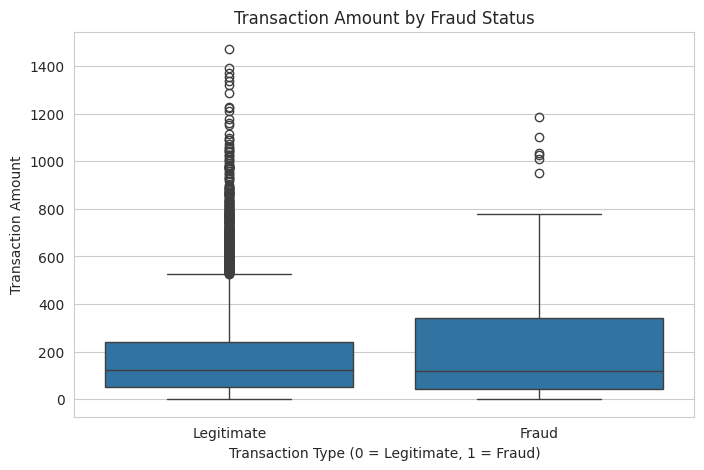

In [44]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df,x="is_fraud",y="amount")
plt.title("Transaction Amount by Fraud Status")
plt.xlabel("Transaction Type (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.show()

### 5.3 Transaction Hour Analysis

Transaction time may help identify patterns in fraudulent activity.

We compare the number of fraudulent and legitimate transactions
across different hours of the day.

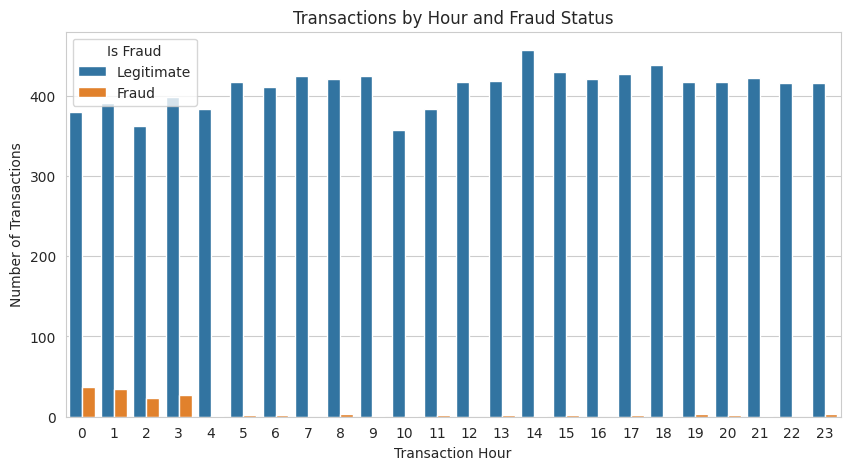

In [45]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df,x="transaction_hour",hue="is_fraud")
plt.title("Transactions by Hour and Fraud Status")
plt.xlabel("Transaction Hour")
plt.ylabel("Number of Transactions")
plt.legend(title="Is Fraud", labels=["Legitimate", "Fraud"])
plt.show()

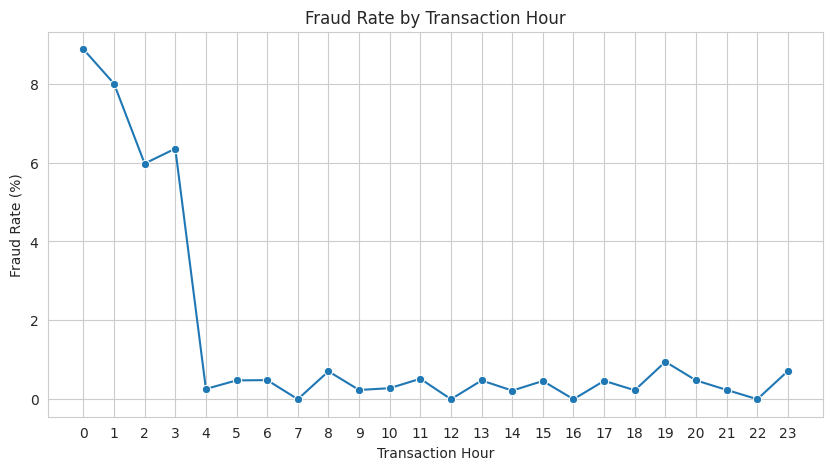

In [46]:
hourly_fraud_rate = (df.groupby("transaction_hour")["is_fraud"].mean() * 100)
plt.figure(figsize=(10, 5))
sns.lineplot(x=hourly_fraud_rate.index,y=hourly_fraud_rate.values,marker="o")
plt.title("Fraud Rate by Transaction Hour")
plt.xlabel("Transaction Hour")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(0, 24))
plt.show()

### 5.4 Merchant Category Analysis

Different merchant categories may have different transaction patterns.

We examine fraud counts and fraud rates across merchant categories.

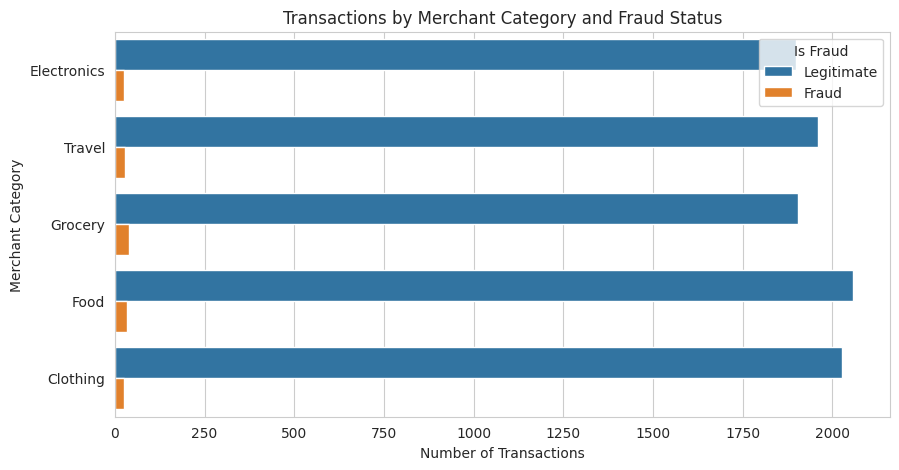

In [47]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df,y="merchant_category",hue="is_fraud")
plt.title("Transactions by Merchant Category and Fraud Status")
plt.xlabel("Number of Transactions")
plt.ylabel("Merchant Category")
plt.legend(title="Is Fraud", labels=["Legitimate", "Fraud"])
plt.show()

In [48]:
category_fraud_rate = (df.groupby("merchant_category")["is_fraud"].agg(["count", "sum", "mean"]))
category_fraud_rate.columns = ["Total Transactions","Fraud Transactions","Fraud Rate"]
category_fraud_rate["Fraud Rate"] *= 100
display(category_fraud_rate.sort_values("Fraud Rate", ascending=False))

,Total Transactions,Fraud Transactions,Fraud Rate
merchant_category,,,
Grocery,1944,39,2.006173
Food,2093,35,1.672241
Travel,1990,29,1.457286
Electronics,1923,24,1.248050
Clothing,2050,24,1.170732


### 5.5 Transaction Risk Indicators

Foreign transactions and location mismatches may be useful indicators
for identifying suspicious activity.

We compare the fraud rate for each of these binary features.

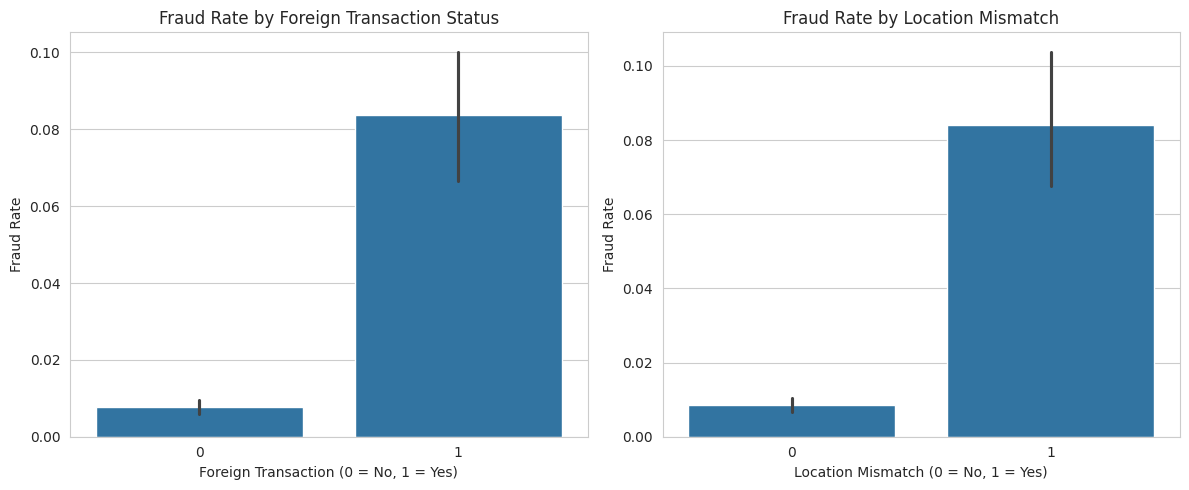

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=df,x="foreign_transaction",y="is_fraud",ax=axes[0])
axes[0].set_title("Fraud Rate by Foreign Transaction Status")
axes[0].set_xlabel("Foreign Transaction (0 = No, 1 = Yes)")
axes[0].set_ylabel("Fraud Rate")
sns.barplot(data=df,x="location_mismatch",y="is_fraud",ax=axes[1])
axes[1].set_title("Fraud Rate by Location Mismatch")
axes[1].set_xlabel("Location Mismatch (0 = No, 1 = Yes)")
axes[1].set_ylabel("Fraud Rate")
plt.tight_layout()
plt.show()

### 5.6 Correlation Analysis

A correlation heatmap helps us understand linear relationships
between numerical features.

We exclude the transaction identifier because it is not a
meaningful measurement of transaction risk.

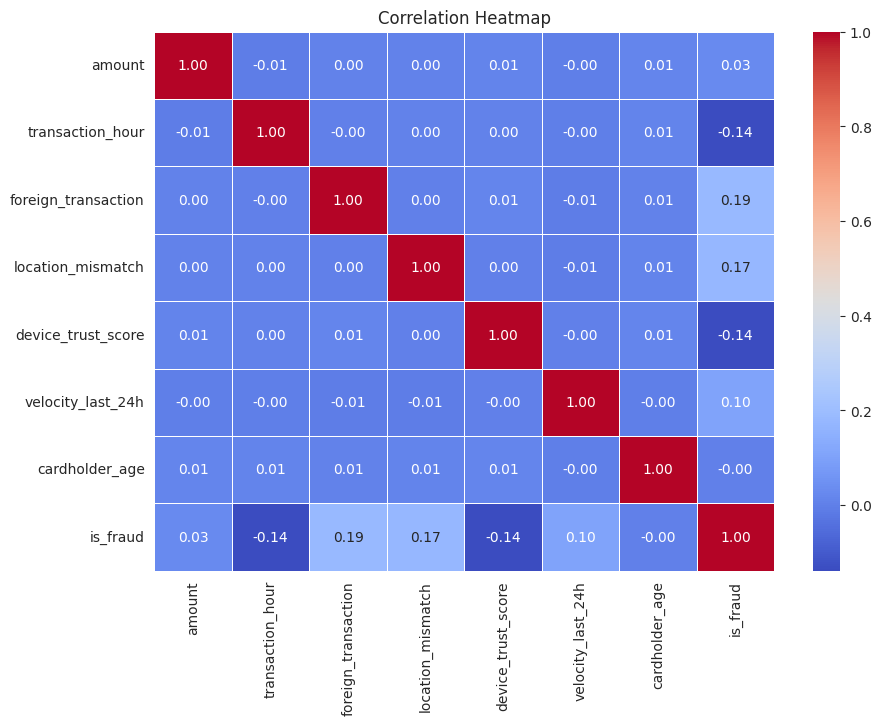

In [50]:
numeric_df = df.select_dtypes(include=np.number).drop(columns=["transaction_id"],errors="ignore")
plt.figure(figsize=(10, 7))
sns.heatmap(numeric_df.corr(),annot=True,cmap="coolwarm",fmt=".2f",linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

## 6. Class Imbalance Analysis

Fraud detection usually involves an unequal distribution of classes.

In this dataset:
- Class 0 represents legitimate transactions.
- Class 1 represents fraudulent transactions.

We calculate the number and percentage of observations in each class.

To address class imbalance, we will use the `class_weight="balanced"`
option for the classification models. This gives greater importance
to the minority class during training.

In [51]:
class_summary = pd.DataFrame({
    "Count": df["is_fraud"].value_counts().sort_index(),
    "Percentage": (df["is_fraud"].value_counts(normalize=True).sort_index() * 100)
})
class_summary.index = ["Legitimate (0)", "Fraud (1)"]
display(class_summary.round(2))

,Count,Percentage
Legitimate (0),9849,98.49
Fraud (1),151,1.51


## 7. Feature Engineering and Preprocessing

The target variable is `is_fraud`.

We exclude:
- `is_fraud`, because it is the target and must not be used as an input.
- `transaction_id`, because it is an identifier and may cause the
  model to learn meaningless patterns.

The `merchant_category` feature is categorical, so we use one-hot
encoding to convert its categories into numerical features.

Numerical features are standardized for Logistic Regression.
Tree-based models do not require feature scaling, but we use the same
preprocessing pipeline structure for convenient model comparison.

In [52]:
# Separate input features and target
X = df.drop(columns=["is_fraud", "transaction_id"])
y = df["is_fraud"]

# Identify feature types
categorical_features = ["merchant_category"]
numerical_features = [col for col in X.columns
    if col not in categorical_features
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

Numerical features: ['amount', 'transaction_hour', 'foreign_transaction', 'location_mismatch', 'device_trust_score', 'velocity_last_24h', 'cardholder_age']
Categorical features: ['merchant_category']

Input shape: (10000, 8)
Target shape: (10000,)


In [53]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numerical_features),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 8. Split the Dataset

We divide the dataset into:
- 80% training data.
- 20% testing data.

Stratified sampling preserves approximately the same fraud-to-legitimate
transaction ratio in both sets.

This is especially important because fraudulent transactions are rare.

The test set is kept separate so that we can evaluate how well the
trained models perform on unseen transactions.

In [54]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nFraud percentage in training data:")
print(round(y_train.mean() * 100, 2), "%")
print("\nFraud percentage in testing data:")
print(round(y_test.mean() * 100, 2), "%")

Training samples: 8000
Testing samples: 2000

Fraud percentage in training data:
1.51 %

Fraud percentage in testing data:
1.5 %


## 9. Model Training

We train three classification algorithms:
1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

All three models use balanced class weights to help account for
the low number of fraudulent transactions.

The preprocessing and classifier are combined into a Pipeline.
This ensures that encoding and scaling are fitted only on the
training data and then applied consistently to the test data.

In [55]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced",max_iter=2000,random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced",max_depth=8,random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200,class_weight="balanced",random_state=42,n_jobs=-1)
}
trained_models = {}
for name, model in models.items():
    pipeline = Pipeline([("preprocessor", preprocessor),("classifier", model)])
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


## 10. Model Evaluation

We evaluate each model using several metrics.

- Accuracy: proportion of all transactions classified correctly.
- Precision: proportion of predicted fraud transactions that are actually fraud.
- Recall: proportion of actual fraud transactions detected.
- F1-score: harmonic mean of precision and recall.
- ROC-AUC: measures how well the model ranks positive cases across thresholds.
- Average Precision: summarizes the precision-recall curve and is particularly
  useful when the positive class is rare.

In fraud detection, recall is important because missed fraud cases can
be costly. Precision is also important because too many false alarms
can inconvenience legitimate customers.

In [56]:
results = []
for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(y_test, y_prob)
    })
results_df = pd.DataFrame(results)
display(results_df.sort_values("F1-Score", ascending=False).round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision
1,Decision Tree,0.9995,0.9677,1.0000,0.9836,0.9997,0.9677
2,Random Forest,0.9930,1.0000,0.5333,0.6957,1.0000,1.0000
0,Logistic Regression,0.9580,0.2589,0.9667,0.4085,0.9933,0.7364


### 10.1 Classification Report

The classification report shows precision, recall, F1-score, and
support for each class.

We pay special attention to class 1, representing fraudulent transactions,
because this is the minority class of interest.

In [57]:
for name, model in trained_models.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    y_pred = model.predict(X_test)
    print(classification_report(y_test,y_pred,target_names=["Legitimate", "Fraud"],zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

  Legitimate       1.00      0.96      0.98      1970
       Fraud       0.26      0.97      0.41        30

    accuracy                           0.96      2000
   macro avg       0.63      0.96      0.69      2000
weighted avg       0.99      0.96      0.97      2000

Decision Tree
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      1970
       Fraud       0.97      1.00      0.98        30

    accuracy                           1.00      2000
   macro avg       0.98      1.00      0.99      2000
weighted avg       1.00      1.00      1.00      2000

Random Forest
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      1.00      1970
       Fraud       1.00      0.53      0.70        30

    accuracy                           0.99      2000
   macro avg       1.00      0.77      0.85      2000
weighted avg       0.99   

### 10.2 Confusion Matrix

A confusion matrix shows four outcomes:

- True Negative (TN): legitimate transactions correctly identified.
- False Positive (FP): legitimate transactions incorrectly flagged as fraud.
- False Negative (FN): fraudulent transactions missed by the model.
- True Positive (TP): fraudulent transactions correctly detected.

False negatives are particularly important in fraud detection because
they represent fraudulent transactions that the model fails to identify.

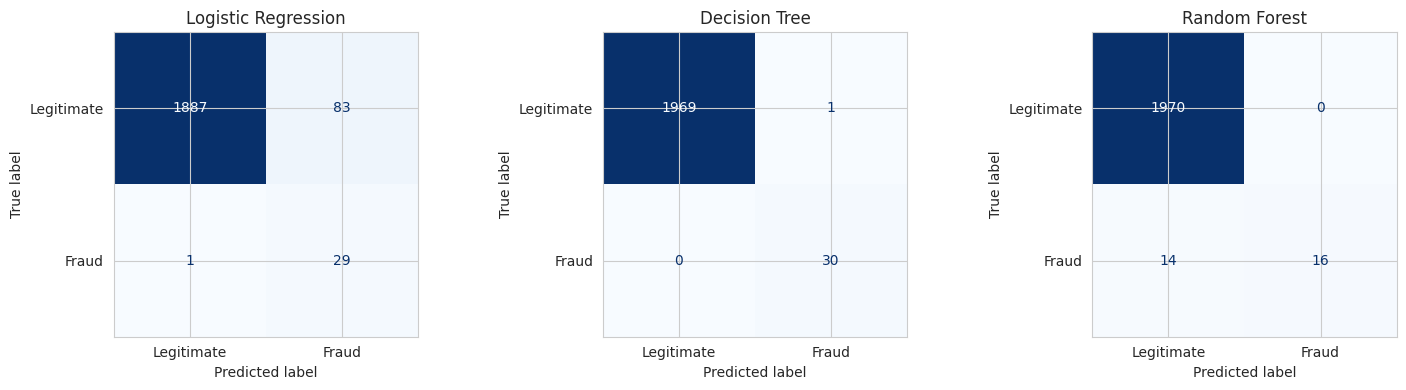

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, trained_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test,y_pred,labels=[0, 1])
    ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Legitimate", "Fraud"]).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 11. Model Comparison

We compare the three models using accuracy, precision, recall,
F1-score, ROC-AUC, and Average Precision.

For this project, fraud-class detection is more important than
accuracy alone.

The best model should be selected based on the evaluation results
and the business trade-off between missed fraud and false alarms.

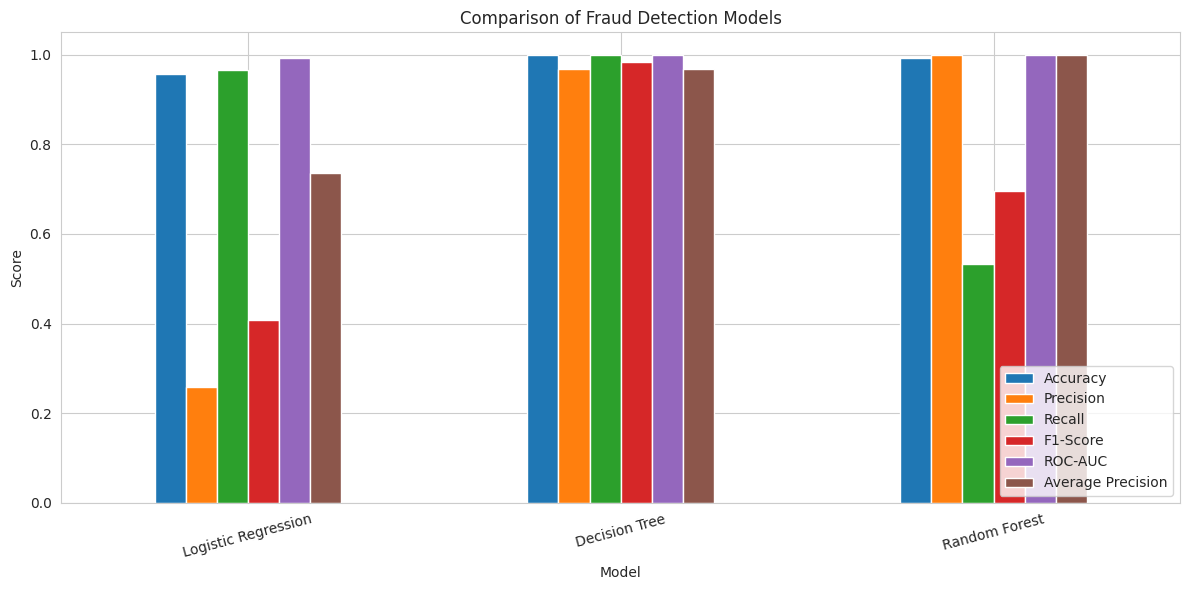

In [59]:
comparison_metrics = ["Accuracy","Precision","Recall","F1-Score","ROC-AUC","Average Precision"]
results_plot = results_df.set_index("Model")[comparison_metrics]
results_plot.plot(kind="bar",figsize=(12, 6))
plt.title("Comparison of Fraud Detection Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [60]:
best_model_row = results_df.sort_values("F1-Score",ascending=False).iloc[0]
print("Best model by F1-score:", best_model_row["Model"])
print("Accuracy:", round(best_model_row["Accuracy"], 4))
print("Precision:", round(best_model_row["Precision"], 4))
print("Recall:", round(best_model_row["Recall"], 4))
print("F1-score:", round(best_model_row["F1-Score"], 4))
print("ROC-AUC:", round(best_model_row["ROC-AUC"], 4))
print("Average Precision:",round(best_model_row["Average Precision"], 4))

Best model by F1-score: Decision Tree
Accuracy: 0.9995
Precision: 0.9677
Recall: 1.0
F1-score: 0.9836
ROC-AUC: 0.9997
Average Precision: 0.9677


## 12. Feature Importance

Feature importance helps identify which input variables contribute
most to the Random Forest model's predictions.

We extract the importance values after preprocessing so that the
categorical merchant categories are represented separately.

Feature importance indicates how the model uses features; it does
not prove that a feature causes fraud.

In [61]:
rf_pipeline = trained_models["Random Forest"]

# Extract preprocessing and classifier steps
fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_classifier = rf_pipeline.named_steps["classifier"]

# Get names of transformed features
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Random Forest importance scores
importance_values = rf_classifier.feature_importances_
importance_df = pd.DataFrame({"Feature": feature_names,"Importance": importance_values}).sort_values("Importance", ascending=False)
display(importance_df.head(15))

,Feature,Importance
1,num__transaction_hour,0.261755
4,num__device_trust_score,0.250905
5,num__velocity_last_24h,0.136244
2,num__foreign_transaction,0.129086
3,num__location_mismatch,0.108888
0,num__amount,0.053607
6,num__cardholder_age,0.032529
11,cat__merchant_category_Travel,0.007077
10,cat__merchant_category_Grocery,0.005687
8,cat__merchant_category_Electronics,0.005658


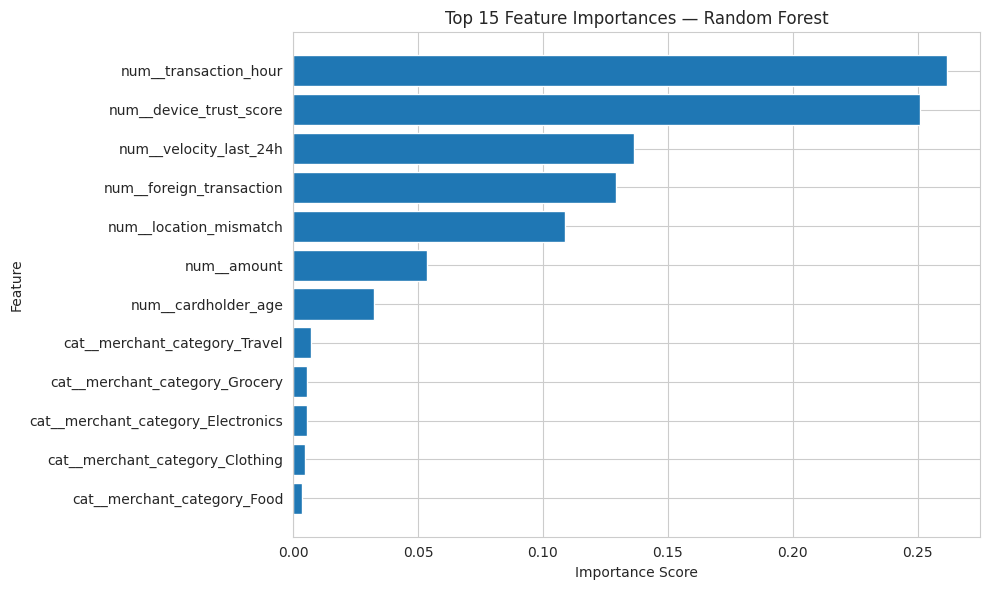

In [62]:
top_features = importance_df.head(15).sort_values("Importance",ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"],top_features["Importance"])
plt.title("Top 15 Feature Importances — Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 13. Export Results

We save the model comparison table and feature importance table
as CSV files for future reference.

In [63]:
results_df.to_csv("fraud_detection_model_comparison.csv",index=False)
importance_df.to_csv("fraud_detection_feature_importance.csv",index=False)
print("Results saved successfully!")

Results saved successfully!


In [64]:
from google.colab import files
files.download("fraud_detection_model_comparison.csv")
files.download("fraud_detection_feature_importance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Conclusion

In this project, we developed machine learning models to identify
potentially fraudulent credit card transactions.

The dataset was inspected and analyzed using exploratory data analysis.
We examined transaction amounts, transaction hours, merchant categories,
location mismatch, foreign transaction status, and class distribution.

We trained Logistic Regression, Decision Tree, and Random Forest
classifiers using a preprocessing pipeline and balanced class weights.

The models were evaluated using accuracy, precision, recall, F1-score,
ROC-AUC, Average Precision, classification reports, and confusion matrices.

Because the dataset contains far fewer fraudulent transactions than
legitimate transactions, accuracy alone is not a sufficient measure
of performance. Fraud-class recall and precision are also important.

The most suitable model should be selected from the measured results,
considering its ability to detect fraudulent transactions while
avoiding excessive false alarms.

This project demonstrates how machine learning can support fraud
detection. However, further testing on larger, representative, and
real-world transaction data would be required before deployment.